In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt


In [220]:
folder_path = r"G:\My Drive\no headstage vids"
prev_file = r"17L\17L_2025_05_29_17_05_57_stitchedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120_filtered"
curr_file = r"17L\17L_2025_05_29_17_05_57_stitched_enhancedDLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120_filtered"

In [216]:
print(folder_path + '\\' + prev_file + ".h5")

G:\My Drive\no headstage vids\17L\g:\My Drive\no headstage vids\17L\17L_2025_05_29_17_05_57_stitched_DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120_filtered.h5


In [221]:
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_prev_file = pd.read_hdf(folder_path + '\\' + prev_file + ".h5")
h5_curr_file = pd.read_hdf(folder_path + '\\' + curr_file + ".h5")

In [222]:
h5_curr_file

scorer    DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120  \
bodyparts                                                     nose   
coords                                                           x   
0                                                 221.490479         
1                                                 221.849380         
2                                                 221.849380         
3                                                 221.849380         
4                                                 221.718307         
...                                                      ...         
16906                                             637.763855         
16907                                             638.209778         
16908                                             639.034485         
16909                                             639.034485         
16910                                             638.209778         

scorer                                                               \
bodyparts                            midbody                          
coords              y likelihood           x           y likelihood   
0          520.911865   0.085744  732.321533  571.862793   0.137726   
1          520.987549   0.110410  732.338928  571.982361   0.118473   
2          521.144653   0.105646  732.380798  572.011963   0.113404   
3          521.144653   0.094549  732.390259  572.030945   0.110286   
4          521.157776   0.089558  732.402344  572.033447   0.113178   
...               ...        ...         ...         ...        ...   
16906       38.106636   0.878393  651.827454   76.603951   0.888825   
16907       38.086975   0.942406  651.768127   76.603951   0.906648   
16908       37.479786   0.898375  651.723877   76.608170   0.907937   
16909       37.343456   0.944660  651.549316   76.603951   0.890454   
16910       37.041950   0.941391  651.504700   76.515862   0.903157   

scorer                                                               \
bodyparts    tailbase                              ear_R              
coords              x           y likelihood           x          y   
0          740.991882  572.372131   0.051679    4.285810  63.477989   
1          740.991882  572.438477   0.047963    4.425480  64.298370   
2          740.991882  572.438477   0.045257    4.551418  64.343422   
3          741.246155  572.438477   0.043326    4.425480  64.343422   
4          741.134216  572.458862   0.043353    4.425480  64.343422   
...               ...         ...        ...         ...        ...   
16906      654.750305   95.167160   0.538610  651.612915  54.504585   
16907      654.750305   95.167160   0.536168  651.693176  55.520203   
16908      654.945190   95.201881   0.528964  651.723694  55.528244   
16909      654.750305   95.201881   0.535329  651.693176  55.528244   
16910      654.750305   95.201881   0.546483  651.693176  55.520203   

scorer                                                  
bodyparts                  ear_L                        
coords    likelihood           x          y likelihood  
0           0.122277    0.755524  61.502460   0.069998  
1           0.133088    0.755524  62.224495   0.080376  
2           0.107492    0.930684  62.236958   0.060589  
3           0.096437    0.755524  62.224495   0.055863  
4           0.096570    0.930684  62.236958   0.059717  
...              ...         ...        ...        ...  
16906       0.831047  638.931152  58.437439   0.664623  
16907       0.870186  638.317871  58.836876   0.665501  
16908       0.838156  638.144226  58.836876   0.653636  
16909       0.862082  638.105225  58.126274   0.665267  
16910       0.846588  638.105225  58.126274   0.660739  

[16911 rows x 15 columns]

In [223]:
# Update to be the actual file name according to the first index column value of the h5 table
prev_file_name = 'DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120'
curr_file_name = 'DLC_Resnet101_NoHeadStage2CamsJun11shuffle1_snapshot_120'

# Load the DataFrame from the HDF5 file
dlc_raw_prev_h5 = h5_prev_file[prev_file_name]
dlc_raw_curr_h5 = h5_curr_file[curr_file_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_prev_h5.iloc[0], dlc_raw_prev_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_prev_h5 = dlc_raw_prev_h5.apply(pd.to_numeric, errors='coerce')
dlc_raw_curr_h5 = dlc_raw_curr_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

prev_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_prev_h5)), columns=new_index)
curr_new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_curr_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_prev_h5 = pd.concat([dlc_raw_prev_h5, prev_new_index_df], axis=1)
dlc_raw_curr_h5 = pd.concat([dlc_raw_curr_h5, curr_new_index_df], axis=1)

dlc_raw_prev_h5


nose                           midbody                         \
                 x          y likelihood           x           y likelihood   
0        26.151314  66.917587   0.269620   44.451481   63.516403   0.236678   
1      1167.843628  66.917587   0.289727   44.636971   63.855759   0.170294   
2      1167.961548  66.989700   0.272084   44.922554   64.119034   0.168455   
3      1167.961548  66.989700   0.263204   44.922554   64.119034   0.145858   
4      1167.972168  66.917587   0.266818   44.922554   64.119034   0.173488   
...            ...        ...        ...         ...         ...        ...   
16906   739.289673  97.586136   0.983988  750.910950  135.911179   0.834006   
16907   739.513916  97.747559   0.976537  750.626709  136.022202   0.821281   
16908   739.779602  97.747559   0.986094  750.614868  136.051559   0.815145   
16909   739.779602  97.747559   0.983285  750.514160  136.051559   0.809595   
16910   739.289673  97.585945   0.976748  750.384338  136.022202   0.822554   

         tailbase                              ear_R                         \
                x           y likelihood           x           y likelihood   
0       40.905186   73.466118   0.200464   22.953306   65.260101   0.193131   
1       40.905186   73.897789   0.168905   23.284477   65.323227   0.225470   
2       40.917625   73.952232   0.177815   23.740488   65.719955   0.205813   
3       41.103233   73.897789   0.171051   23.856560   66.011459   0.190305   
4       41.103233   73.897789   0.185464   23.856560   66.011459   0.208679   
...           ...         ...        ...         ...         ...        ...   
16906  753.180054  153.732300   0.579768  752.674011  112.937180   0.848723   
16907  753.180054  153.755966   0.572423  752.282898  114.070801   0.845705   
16908  753.180054  153.777893   0.575868  752.262939  114.070801   0.839676   
16909  753.180054  153.777893   0.591273  752.107056  114.070801   0.831681   
16910  752.966370  153.777893   0.593766  752.097046  114.009598   0.830684   

            ear_L                        weighted                 
                x           y likelihood        x   y likelihood  
0       27.716103   67.202805   0.155092      NaN NaN        NaN  
1       28.475485   67.406197   0.179251      NaN NaN        NaN  
2       28.638744   67.501259   0.159643      NaN NaN        NaN  
3       28.638744   67.559456   0.143248      NaN NaN        NaN  
4       28.475485   69.707397   0.160077      NaN NaN        NaN  
...           ...         ...        ...      ...  ..        ...  
16906  739.616943  118.735100   0.893139      NaN NaN        NaN  
16907  739.191284  118.804817   0.869305      NaN NaN        NaN  
16908  739.178650  118.804817   0.875264      NaN NaN        NaN  
16909  739.076721  118.804817   0.866261      NaN NaN        NaN  
16910  738.841370  118.654297   0.868726      NaN NaN        NaN  

[16911 rows x 18 columns]

In [224]:
dlc_raw_curr_h5

nose                            midbody                         \
                x           y likelihood           x           y likelihood   
0      221.490479  520.911865   0.085744  732.321533  571.862793   0.137726   
1      221.849380  520.987549   0.110410  732.338928  571.982361   0.118473   
2      221.849380  521.144653   0.105646  732.380798  572.011963   0.113404   
3      221.849380  521.144653   0.094549  732.390259  572.030945   0.110286   
4      221.718307  521.157776   0.089558  732.402344  572.033447   0.113178   
...           ...         ...        ...         ...         ...        ...   
16906  637.763855   38.106636   0.878393  651.827454   76.603951   0.888825   
16907  638.209778   38.086975   0.942406  651.768127   76.603951   0.906648   
16908  639.034485   37.479786   0.898375  651.723877   76.608170   0.907937   
16909  639.034485   37.343456   0.944660  651.549316   76.603951   0.890454   
16910  638.209778   37.041950   0.941391  651.504700   76.515862   0.903157   

         tailbase                              ear_R                        \
                x           y likelihood           x          y likelihood   
0      740.991882  572.372131   0.051679    4.285810  63.477989   0.122277   
1      740.991882  572.438477   0.047963    4.425480  64.298370   0.133088   
2      740.991882  572.438477   0.045257    4.551418  64.343422   0.107492   
3      741.246155  572.438477   0.043326    4.425480  64.343422   0.096437   
4      741.134216  572.458862   0.043353    4.425480  64.343422   0.096570   
...           ...         ...        ...         ...        ...        ...   
16906  654.750305   95.167160   0.538610  651.612915  54.504585   0.831047   
16907  654.750305   95.167160   0.536168  651.693176  55.520203   0.870186   
16908  654.945190   95.201881   0.528964  651.723694  55.528244   0.838156   
16909  654.750305   95.201881   0.535329  651.693176  55.528244   0.862082   
16910  654.750305   95.201881   0.546483  651.693176  55.520203   0.846588   

            ear_L                       weighted                 
                x          y likelihood        x   y likelihood  
0        0.755524  61.502460   0.069998      NaN NaN        NaN  
1        0.755524  62.224495   0.080376      NaN NaN        NaN  
2        0.930684  62.236958   0.060589      NaN NaN        NaN  
3        0.755524  62.224495   0.055863      NaN NaN        NaN  
4        0.930684  62.236958   0.059717      NaN NaN        NaN  
...           ...        ...        ...      ...  ..        ...  
16906  638.931152  58.437439   0.664623      NaN NaN        NaN  
16907  638.317871  58.836876   0.665501      NaN NaN        NaN  
16908  638.144226  58.836876   0.653636      NaN NaN        NaN  
16909  638.105225  58.126274   0.665267      NaN NaN        NaN  
16910  638.105225  58.126274   0.660739      NaN NaN        NaN  

[16911 rows x 18 columns]

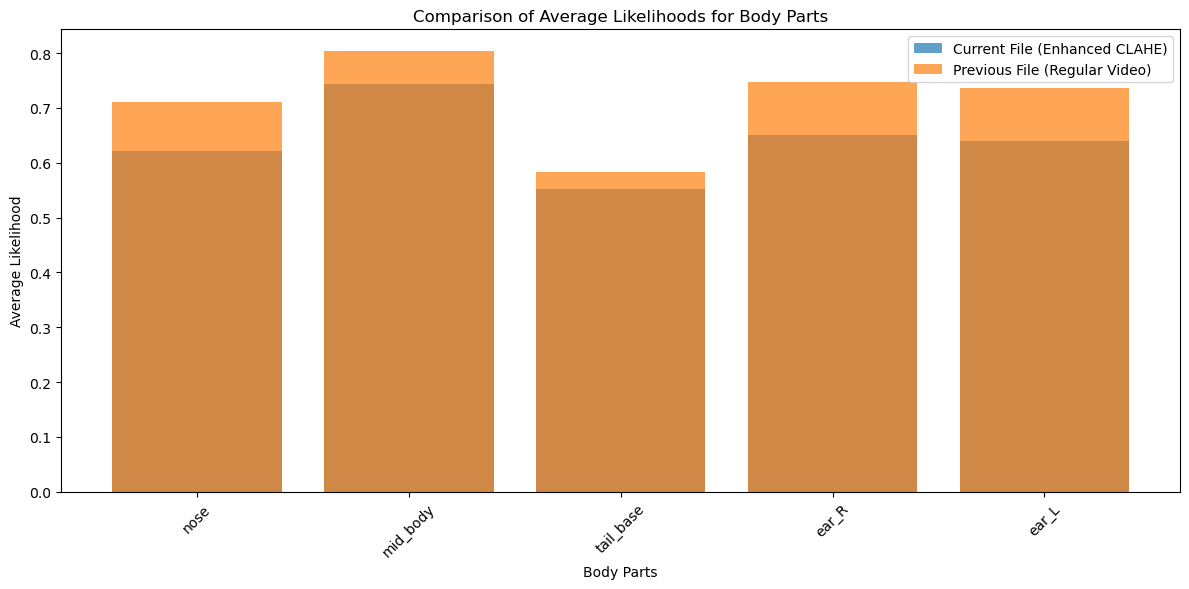

In [ ]:
# Extract likelihood columns for both datasets
curr_likelihoods = dlc_raw_curr_h5.xs('likelihood', level=1, axis=1)
prev_likelihoods = dlc_raw_prev_h5.xs('likelihood', level=1, axis=1)

# Drop the 'weighted' column from both datasets
curr_likelihoods = curr_likelihoods.drop(columns=['weighted'])
prev_likelihoods = prev_likelihoods.drop(columns=['weighted'])

# Rename columns to merge names with '_'
curr_likelihoods.columns = curr_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
prev_likelihoods.columns = prev_likelihoods.columns.str.replace('midbody', 'mid_body').str.replace('tailbase', 'tail_base')
# Calculate average likelihoods for each body part
curr_avg_likelihoods = curr_likelihoods.mean()
prev_avg_likelihoods = prev_likelihoods.mean()

# Plot the average likelihoods for comparison
plt.figure(figsize=(12, 6))
plt.bar(curr_avg_likelihoods.index, curr_avg_likelihoods, alpha=0.7, label='Current File')
plt.bar(prev_avg_likelihoods.index, prev_avg_likelihoods, alpha=0.7, label='Previous File')
plt.xlabel('Body Parts')
plt.ylabel('Average Likelihood')
plt.title('Comparison of Average Likelihoods for Body Parts')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

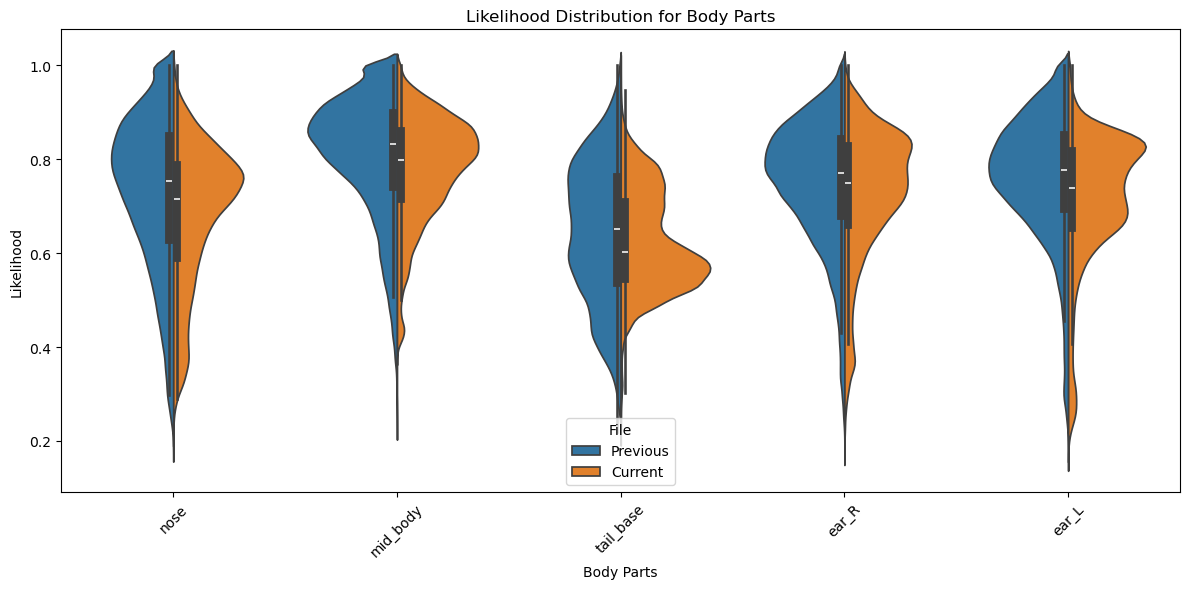

In [17]:
import seaborn as sns

# Combine the likelihood data into a single DataFrame for plotting
combined_likelihoods = pd.concat([
    prev_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Previous'),
    curr_likelihoods.melt(var_name='Body Part', value_name='Likelihood').assign(File='Current')
])

# Create the violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=combined_likelihoods, x='Body Part', y='Likelihood', hue='File', split=True)
plt.title('Likelihood Distribution for Body Parts')
plt.xlabel('Body Parts')
plt.ylabel('Likelihood')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from itertools import combinations

# Define bodyparts to check
bodyparts = ['nose', 'midbody', 'tailbase', 'ear_R', 'ear_L']

# 1. Inter-bodypart distance outlier detection
# Calculate average distance between each pair of bodyparts across all frames

# Get coordinates for each bodypart
coords = {bp: np.stack([dlc_raw_curr_h5[(bp, 'x')], dlc_raw_curr_h5[(bp, 'y')]], axis=1) for bp in bodyparts}

# Compute mean distance for each pair
pairwise_means = {}
pairwise_medians = {}
for bp1, bp2 in combinations(bodyparts, 2):
    dists = np.linalg.norm(coords[bp1] - coords[bp2], axis=1)
    pairwise_means[(bp1, bp2)] = dists.mean()
    pairwise_medians[(bp1, bp2)] = np.median(dists)  # Using median for more robust outlier detection

# For each frame, check if any pair is > 3x median distance
# outlier_matrix_dist = pd.DataFrame(False, index=dlc_raw_curr_h5.index, columns=bodyparts)
# for bp1, bp2 in combinations(bodyparts, 2):
#     dists = np.linalg.norm(coords[bp1] - coords[bp2], axis=1)
#     outlier_frames = dists > 3 * pairwise_medians[(bp1, bp2)]
#     # Mark both bodyparts as outlier in these frames
#     outlier_matrix_dist.loc[outlier_frames, bp1] = True
#     outlier_matrix_dist.loc[outlier_frames, bp2] = True

# 2. Jump outlier detection (frame-to-frame movement)
# outlier_matrix_jump = pd.DataFrame(False, index=dlc_raw_curr_h5.index, columns=bodyparts)
# for bp in bodyparts:
#     xy = coords[bp]
#     jumps = np.linalg.norm(xy[1:] - xy[:-1], axis=1)
#     mean_jump = jumps.mean()
#     median_jump = np.median(jumps)
#     max_jump = jumps.max()
#     # Outlier if jump > 3 times median jump
#     outlier_idx = np.where(jumps > median_jump * 3)[0] + 1  # +1 because jump is from frame i-1 to i
#     outlier_matrix_jump.loc[outlier_idx, bp] = True

# Combine both outlier matrices
# outlier_matrix = outlier_matrix_dist | outlier_matrix_jump

expected_means = {}
for bp in bodyparts:
    # For each frame, compute mean distance from bp to all others
    dists = []
    for i in range(len(dlc_raw_curr_h5)):
        others = [other for other in bodyparts if other != bp]
        d = [np.linalg.norm(coords[bp][i] - coords[other][i]) for other in others]
        dists.append(np.mean(d))
    expected_means[bp] = np.median(dists)

# For each frame, check which bodyparts are outliers
outlier_bodyparts = []
for i in range(len(dlc_raw_curr_h5)):
    frame_outliers = []
    for bp in bodyparts:
        others = [other for other in bodyparts if other != bp]
        d = [np.linalg.norm(coords[bp][i] - coords[other][i]) for other in others]
        mean_dist = np.mean(d)
        if i == 2159:
            print(f"Frame {i}, Bodypart {bp}, Mean Distance: {mean_dist}, Expected Mean: {expected_means[bp]}")
        if mean_dist > 3 * expected_means[bp]:
            frame_outliers.append(bp)
    outlier_bodyparts.append(frame_outliers)

# Add the list of outlier bodyparts as a new column
dlc_raw_curr_h5['distance_outlier_bodyparts'] = outlier_bodyparts

# Example: Show frames with any outlier
print(dlc_raw_curr_h5[dlc_raw_curr_h5['distance_outlier_bodyparts'].apply(len) > 0][['distance_outlier_bodyparts']].head())

# Show summary of outliers per bodypart
# outlier_counts = outlier_matrix.sum()
# print("Outlier counts per bodypart:")
# print(outlier_counts)

# Optionally, show frames with any outlier
# outlier_frames = outlier_matrix.any(axis=1)
# print(f"Total frames with any outlier: {outlier_frames.sum()}")

# print("Total frames in dataset:", len(dlc_raw_curr_h5))

# outlier_matrix is a DataFrame (frames x bodyparts) with True for outlier labels

Frame 2159, Bodypart nose, Mean Distance: 748.7122802734375, Expected Mean: 41.442779541015625
Frame 2159, Bodypart midbody, Mean Distance: 361.214111328125, Expected Mean: 34.708499908447266
Frame 2159, Bodypart tailbase, Mean Distance: 306.8400573730469, Expected Mean: 56.33837127685547
Frame 2159, Bodypart ear_R, Mean Distance: 283.0361328125, Expected Mean: 31.562780380249023
Frame 2159, Bodypart ear_L, Mean Distance: 290.4951477050781, Expected Mean: 31.058082580566406


ValueError: Length of values (168698) does not match length of index (77549)

In [204]:
print("nose coords 2159:", coords['nose'][2159])
others = [other for other in bodyparts if other != 'nose']
d = [np.linalg.norm(coords['nose'][i] - coords[other][i]) for other in others]
print("Distances from nose to others at frame 2159:", d)
mean_dist = np.mean(d)
print("Mean distance from nose to others at frame 2159:", mean_dist)

nose coords 2159: [  6.3231125 992.28656  ]
Distances from nose to others at frame 2159: [40.6787, 70.04046, 15.097214, 15.011868]
Mean distance from nose to others at frame 2159: 35.20706


In [195]:
expected_means

{'nose': 41.44278,
 'midbody': 34.7085,
 'tailbase': 56.33837,
 'ear_R': 31.56278,
 'ear_L': 31.058083}

In [166]:
dlc_raw_curr_h5[7341:7342]

nose                            midbody                         \
               x           y likelihood           x           y likelihood   
7341  158.681335  594.301636   0.524234  168.222046  617.169983   0.815054   

        tailbase                             ear_R                         \
               x          y likelihood           x           y likelihood   
7341  175.989075  633.73761   0.596958  165.796127  606.933411   0.597947   

           ear_L                        weighted                 \
               x           y likelihood        x   y likelihood   
7341  156.131653  610.075806   0.655746      NaN NaN        NaN   

     distance_outlier_bodyparts  
                                 
7341                         []

In [155]:
# Create a DataFrame with only the frames that are outliers
outlier_frames_df = dlc_raw_curr_h5[outlier_frames].copy()
# Add a column with the original index
outlier_frames_df['original_index'] = outlier_frames_df.index
outlier_frames_df

nose                            midbody                         \
                x           y likelihood           x           y likelihood   
0        7.488315  992.001404   0.303407   33.275558  142.523743   0.433099   
1        7.777886  991.618652   0.294189   33.528011  142.871521   0.422946   
2        7.536671  991.916016   0.311148   33.476772  142.799011   0.426724   
3        7.410993  992.055786   0.316681   33.491104  142.838318   0.425394   
4        7.614246  991.820984   0.290845   33.559502  142.816833   0.427544   
...           ...         ...        ...         ...         ...        ...   
77544  474.856018  698.971924   0.618399  429.081024  707.174866   0.761768   
77545  477.271088  701.304565   0.525462  434.408203  706.319641   0.917628   
77546  481.044495  704.245117   0.672527  437.373016  705.286499   0.871607   
77547  481.774994  706.226685   0.621763  440.195160  705.678162   0.821131   
77548  483.485199  707.519653   0.654302  442.838135  705.915649   0.843843   

          tailbase                               ear_R                         \
                 x           y likelihood            x           y likelihood   
0        13.518434  275.254608   0.469136  1230.934082  932.431091   0.371297   
1        13.458936  275.289673   0.472990  1229.705444  937.662720   0.280459   
2      1131.352417   37.682228   0.463230  1229.682617  937.602661   0.287565   
3        13.631626  274.874054   0.457493  1229.805908  937.543701   0.285610   
4      1130.845947   37.377689   0.495043  1229.729004  937.585022   0.297318   
...            ...         ...        ...          ...         ...        ...   
77544   398.884277  707.687439   0.636862   459.580811  710.078125   0.604517   
77545  1008.447571   21.392534   0.579608   463.772308  710.548889   0.569700   
77546  1008.433838   21.303625   0.583089   466.408722  710.974243   0.756703   
77547   410.990234  706.564697   0.650622   467.797333  711.881042   0.719557   
77548   413.477051  705.392395   0.639792   469.238281  712.514771   0.746611   

             ear_L                        weighted                 \
                 x           y likelihood        x   y likelihood   
0      1245.637573  940.105164   0.267320      NaN NaN        NaN   
1      1245.890991  940.448120   0.232109      NaN NaN        NaN   
2      1245.779053  940.553162   0.237785      NaN NaN        NaN   
3      1245.842896  940.433167   0.228468      NaN NaN        NaN   
4      1245.751343  940.576172   0.238390      NaN NaN        NaN   
...            ...         ...        ...      ...  ..        ...   
77544   457.026184  697.230957   0.590487      NaN NaN        NaN   
77545   463.153320  698.239563   0.593893      NaN NaN        NaN   
77546   466.448578  697.515137   0.763159      NaN NaN        NaN   
77547   468.424164  698.707092   0.688539      NaN NaN        NaN   
77548   471.136322  698.983765   0.745771      NaN NaN        NaN   

      original_index  
                      
0                  0  
1                  1  
2                  2  
3                  3  
4                  4  
...              ...  
77544          77544  
77545          77545  
77546          77546  
77547          77547  
77548          77548  

[56455 rows x 19 columns]

In [84]:
from collections import Counter

# Find sequences of consecutive frames with any outlier
outlier_bool = outlier_frames.values  # Convert to numpy array for efficient processing

# Find the start and end indices of each sequence
diff = np.diff(outlier_bool.astype(int))
starts = np.where(diff == 1)[0] + 1 if outlier_bool[0] == False else np.insert(np.where(diff == 1)[0] + 1, 0, 0)
ends = np.where(diff == -1)[0] + 1 if outlier_bool[-1] == False else np.append(np.where(diff == -1)[0] + 1, len(outlier_bool))

# If the first frame is an outlier, ensure the first sequence starts at 0
if outlier_bool[0]:
    starts = np.insert(starts, 0, 0)
# If the last frame is an outlier, ensure the last sequence ends at the last index
if outlier_bool[-1]:
    ends = np.append(ends, len(outlier_bool))

# Calculate sequence lengths
seq_lengths = ends - starts

# Count the number of sequences for each length
length_counts = Counter(seq_lengths)

# Convert to DataFrame for easier viewing (optional)
seq_length_df = pd.DataFrame.from_dict(length_counts, orient='index', columns=['count']).sort_index()
seq_length_df.index.name = 'sequence_length'
seq_length_df

,count
sequence_length,
3,195
4,214
5,261
6,213
7,170
...,...
716,1
798,1
885,1


In [63]:
outlier_matrix_dist.sum()

nose        33824
midbody     34281
tailbase    34277
ear_R       34251
ear_L       34273
dtype: int64

In [60]:
outlier_matrix_jump.sum()

nose        17408
midbody     17372
tailbase    25769
ear_R       16698
ear_L       15624
dtype: int64

In [53]:
perc90_jump

7.589806151390073

In [37]:
mean_jump

14.42465

In [57]:
median_jump

1.2471712

In [54]:
pairwise_means

{('nose', 'midbody'): 122.97814,
 ('nose', 'tailbase'): 419.60416,
 ('nose', 'ear_R'): 56.670544,
 ('nose', 'ear_L'): 61.768192,
 ('midbody', 'tailbase'): 353.39136,
 ('midbody', 'ear_R'): 88.81614,
 ('midbody', 'ear_L'): 78.21126,
 ('tailbase', 'ear_R'): 395.91968,
 ('tailbase', 'ear_L'): 389.17435,
 ('ear_R', 'ear_L'): 31.638271}

In [55]:
pairwise_medians

{('nose', 'midbody'): 41.597404,
 ('nose', 'tailbase'): 76.50423,
 ('nose', 'ear_R'): 19.494696,
 ('nose', 'ear_L'): 19.312119,
 ('midbody', 'tailbase'): 28.942162,
 ('midbody', 'ear_R'): 25.3327,
 ('midbody', 'ear_L'): 24.46187,
 ('tailbase', 'ear_R'): 59.46163,
 ('tailbase', 'ear_L'): 58.10659,
 ('ear_R', 'ear_L'): 14.035453}

C:\Users\Almog\AppData\Local\Temp\ipykernel_3057184\1718618761.py:12: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  outlier_idx = int(outlier_frames_df.iloc[5500]['original_index'])


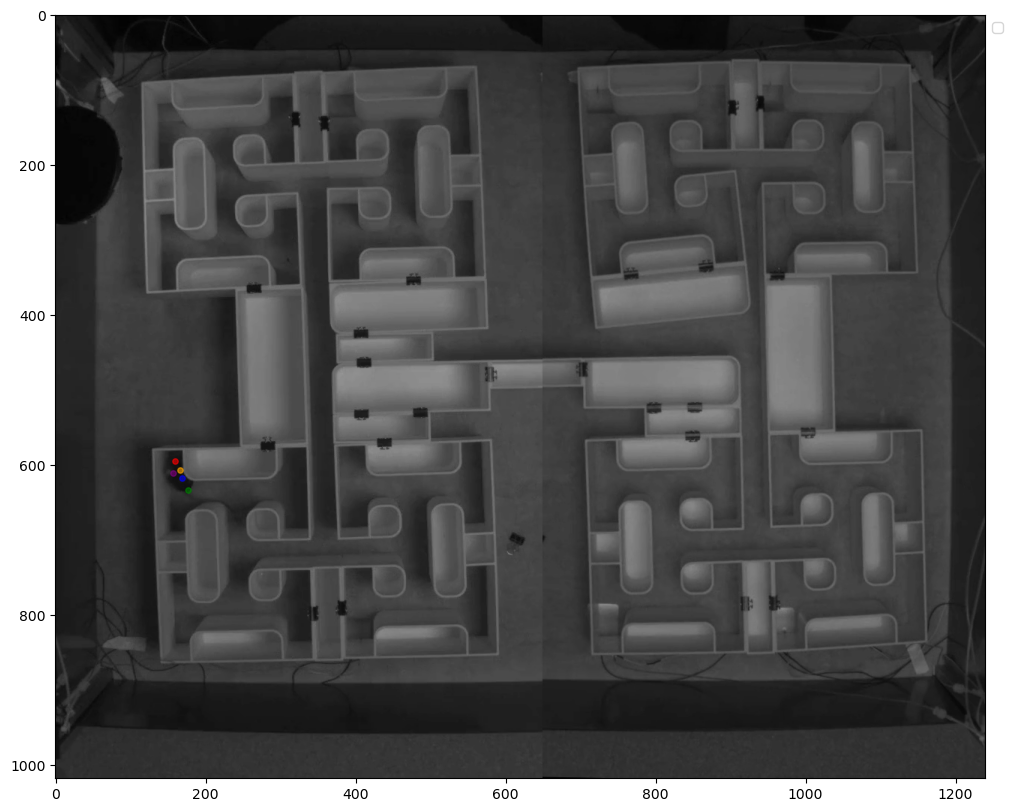

In [ ]:
import cv2
# Prepare color map for bodyparts
color_map = {
    'nose': 'red',
    'midbody': 'blue',
    'tailbase': 'green',
    'ear_R': 'orange',
    'ear_L': 'purple'
}

# Find the n frame index with any outlier in the dist matrix
outlier_idx = int(outlier_frames_df.iloc[5500]['original_index'])
# outlier_idx = 42995

# Read the video file (assume video file is in the same folder and named after curr_file, with .mp4 extension)
video_path = r"G:\My Drive\no headstage vids\18R\18R_2025_06_30_11_25_03_stitched.mp4"
cap = cv2.VideoCapture(video_path)

# Get the frame at outlier_idx (assuming outlier_idx matches video frame index)
cap.set(cv2.CAP_PROP_POS_FRAMES, outlier_idx)
ret, frame_img = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f"Could not read frame {outlier_idx} from {video_path}")

# Convert BGR (OpenCV) to RGB (matplotlib)
frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)
# Remove bodypart text, only plot colored dots.
# Collect handles and labels for legend (only for outlier bodyparts)
handles = []
labels = []

plt.figure(figsize=(12, 12))
plt.imshow(frame_img)
for bp in bodyparts:
    x = dlc_raw_curr_h5.loc[outlier_idx, (bp, 'x')]
    y = dlc_raw_curr_h5.loc[outlier_idx, (bp, 'y')]
    is_out = outlier_matrix_dist.loc[outlier_idx, bp]
    sc = plt.scatter(x, y, color=color_map[bp], marker='.', label=bp if is_out else None, 
                     s=60, edgecolor='black' if is_out else None, alpha=0.6)
    if is_out:
        handles.append(sc)
        labels.append(bp)

plt.legend(handles, labels, loc='upper left', bbox_to_anchor=(1, 1))


In [167]:
from collections import Counter

# Count occurrences of each unique list in the 'distance_outlier_bodyparts' column

outlier_lists = dlc_raw_curr_h5['distance_outlier_bodyparts']
outlier_list_counts = Counter(tuple(lst) for lst in outlier_lists)
print(outlier_list_counts)

Counter({(): 43276, ('nose', 'midbody', 'tailbase', 'ear_R', 'ear_L'): 33349, ('tailbase',): 540, ('midbody', 'tailbase', 'ear_R', 'ear_L'): 277, ('nose', 'midbody', 'ear_R', 'ear_L'): 32, ('tailbase', 'ear_R', 'ear_L'): 26, ('nose', 'ear_R', 'ear_L'): 15, ('tailbase', 'ear_R'): 8, ('nose',): 7, ('midbody',): 6, ('ear_L',): 4, ('midbody', 'tailbase'): 3, ('midbody', 'ear_R', 'ear_L'): 2, ('tailbase', 'ear_L'): 2, ('midbody', 'tailbase', 'ear_R'): 1, ('ear_R', 'ear_L'): 1})


In [168]:
# Save all rows where 'distance_outlier_bodyparts' equals ('nose', 'midbody', 'tailbase', 'ear_R', 'ear_L')
all_outlier_tuple = ('nose', 'midbody', 'tailbase', 'ear_R', 'ear_L')
all_outlier_rows_df = dlc_raw_curr_h5[dlc_raw_curr_h5['distance_outlier_bodyparts'].apply(lambda x: tuple(x) == all_outlier_tuple)].copy()

In [174]:
all_outlier_rows_df

nose                            midbody                         \
                x           y likelihood           x           y likelihood   
0        7.488315  992.001404   0.303407   33.275558  142.523743   0.433099   
1        7.777886  991.618652   0.294189   33.528011  142.871521   0.422946   
2        7.536671  991.916016   0.311148   33.476772  142.799011   0.426724   
3        7.410993  992.055786   0.316681   33.491104  142.838318   0.425394   
4        7.614246  991.820984   0.290845   33.559502  142.816833   0.427544   
...           ...         ...        ...         ...         ...        ...   
77541  463.697113  691.371765   0.391740  420.915710  704.838928   0.779717   
77542  468.087799  692.165466   0.552414  423.039001  705.609741   0.778473   
77543  470.657257  695.543945   0.596789  425.237976  706.769348   0.718784   
77545  477.271088  701.304565   0.525462  434.408203  706.319641   0.917628   
77546  481.044495  704.245117   0.672527  437.373016  705.286499   0.871607   

          tailbase                               ear_R                         \
                 x           y likelihood            x           y likelihood   
0        13.518434  275.254608   0.469136  1230.934082  932.431091   0.371297   
1        13.458936  275.289673   0.472990  1229.705444  937.662720   0.280459   
2      1131.352417   37.682228   0.463230  1229.682617  937.602661   0.287565   
3        13.631626  274.874054   0.457493  1229.805908  937.543701   0.285610   
4      1130.845947   37.377689   0.495043  1229.729004  937.585022   0.297318   
...            ...         ...        ...          ...         ...        ...   
77541  1008.377930   21.676056   0.584390   458.792480  702.669373   0.416325   
77542  1008.443176   21.862314   0.581326   459.608704  706.032471   0.590915   
77543  1008.395081   21.660919   0.584182   459.302277  708.442627   0.677120   
77545  1008.447571   21.392534   0.579608   463.772308  710.548889   0.569700   
77546  1008.433838   21.303625   0.583089   466.408722  710.974243   0.756703   

             ear_L                        weighted                 \
                 x           y likelihood        x   y likelihood   
0      1245.637573  940.105164   0.267320      NaN NaN        NaN   
1      1245.890991  940.448120   0.232109      NaN NaN        NaN   
2      1245.779053  940.553162   0.237785      NaN NaN        NaN   
3      1245.842896  940.433167   0.228468      NaN NaN        NaN   
4      1245.751343  940.576172   0.238390      NaN NaN        NaN   
...            ...         ...        ...      ...  ..        ...   
77541   449.118408  695.006042   0.400351      NaN NaN        NaN   
77542   453.552216  695.751770   0.627464      NaN NaN        NaN   
77543   455.051178  696.703186   0.664602      NaN NaN        NaN   
77545   463.153320  698.239563   0.593893      NaN NaN        NaN   
77546   466.448578  697.515137   0.763159      NaN NaN        NaN   

                    distance_outlier_bodyparts  
                                                
0      [nose, midbody, tailbase, ear_R, ear_L]  
1      [nose, midbody, tailbase, ear_R, ear_L]  
2      [nose, midbody, tailbase, ear_R, ear_L]  
3      [nose, midbody, tailbase, ear_R, ear_L]  
4      [nose, midbody, tailbase, ear_R, ear_L]  
...                                        ...  
77541  [nose, midbody, tailbase, ear_R, ear_L]  
77542  [nose, midbody, tailbase, ear_R, ear_L]  
77543  [nose, midbody, tailbase, ear_R, ear_L]  
77545  [nose, midbody, tailbase, ear_R, ear_L]  
77546  [nose, midbody, tailbase, ear_R, ear_L]  

[33349 rows x 19 columns]

In [187]:
all_outlier_rows_df.iloc[12000]['nose']

x             1232.523926
y              952.849426
likelihood       0.378933
Name: 35486, dtype: object

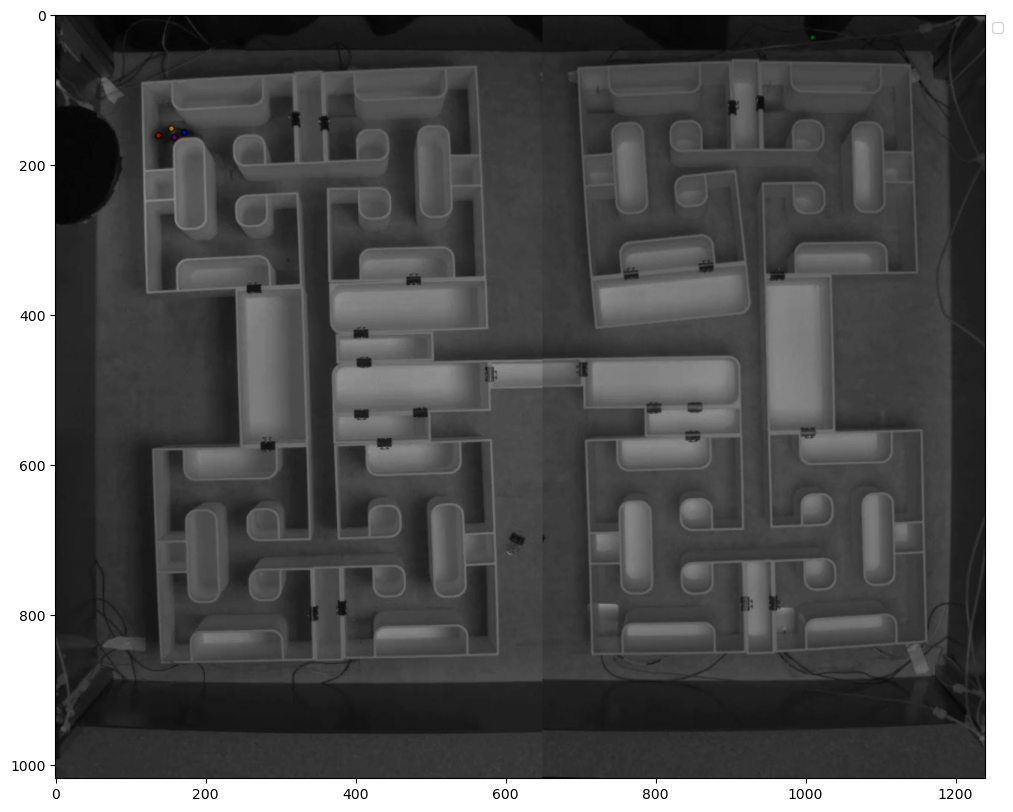

In [ ]:
import cv2
# Prepare color map for bodyparts
color_map = {
    'nose': 'red',
    'midbody': 'blue',
    'tailbase': 'green',
    'ear_R': 'orange',
    'ear_L': 'purple'
}

# Find the n frame index with any outlier in the dist matrix
outlier_idx = 2000

# Read the video file (assume video file is in the same folder and named after curr_file, with .mp4 extension)
video_path = r"G:\My Drive\no headstage vids\18R\18R_2025_06_30_11_25_03_stitched.mp4"
cap = cv2.VideoCapture(video_path)

# Get the frame at outlier_idx (assuming outlier_idx matches video frame index)
cap.set(cv2.CAP_PROP_POS_FRAMES, all_outlier_rows_df.iloc[outlier_idx].name)
ret, frame_img = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f"Could not read frame {outlier_idx} from {video_path}")

# Convert BGR (OpenCV) to RGB (matplotlib)
frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)
# Remove bodypart text, only plot colored dots.
# Collect handles and labels for legend (only for outlier bodyparts)
handles = []
labels = []

plt.figure(figsize=(12, 12))
plt.imshow(frame_img)
for bp in bodyparts:
    x = all_outlier_rows_df.iloc[outlier_idx][(bp, 'x')]
    y = all_outlier_rows_df.iloc[outlier_idx][(bp, 'y')]
    sc = plt.scatter(x, y, color=color_map[bp], marker='.', label=bp, 
                     s=60, edgecolor='black' if is_out else None, alpha=0.6)

plt.legend(handles, labels, loc='upper left', bbox_to_anchor=(1, 1))

In [191]:
outlier_frames_df.iloc[2000]

nose            x                6.323112
                y              992.286560
                likelihood       0.434750
midbody         x               34.756508
                y              142.648193
                likelihood       0.481656
tailbase        x               12.499631
                y              275.167938
                likelihood       0.454345
ear_R           x              190.506531
                y              305.359283
                likelihood       0.589823
ear_L           x              205.624435
                y              304.168457
                likelihood       0.750135
weighted        x                     NaN
                y                     NaN
                likelihood            NaN
original_index                2159.000000
Name: 2159, dtype: float64

In [194]:
dlc_raw_curr_h5.iloc[2159]

nose                        x                                            6.323112
                            y                                           992.28656
                            likelihood                                    0.43475
midbody                     x                                           34.756508
                            y                                          142.648193
                            likelihood                                   0.481656
tailbase                    x                                           12.499631
                            y                                          275.167938
                            likelihood                                   0.454345
ear_R                       x                                          190.506531
                            y                                          305.359283
                            likelihood                                   0.589823
ear_L           